# Predicting Income from Census Data
Predicting whether or not a person makes more than $50,000 in a year, classifying with models that use AdaBoost and GradientBoost algorithms.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [2]:
col_names = [
    'age', 'workclass', 'fnlwgt','education', 'education-num', 'marital-status',
    'occupation', 'relationship', 'race', 'sex', 'capital-gain','capital-loss',
    'hours-per-week','native-country', 'income'
]

target_column = "income"
raw_feature_cols = [
    'age',
    'education-num',
    'workclass',
    'hours-per-week',
    'sex',
    'race'
]

In [3]:
df = pd.read_csv('./Data Files/adults.csv', header=None, names = col_names)
print(df.head())

   age          workclass  fnlwgt   education  education-num  \
0   39          State-gov   77516   Bachelors             13   
1   50   Self-emp-not-inc   83311   Bachelors             13   
2   38            Private  215646     HS-grad              9   
3   53            Private  234721        11th              7   
4   28            Private  338409   Bachelors             13   

        marital-status          occupation    relationship    race      sex  \
0        Never-married        Adm-clerical   Not-in-family   White     Male   
1   Married-civ-spouse     Exec-managerial         Husband   White     Male   
2             Divorced   Handlers-cleaners   Not-in-family   White     Male   
3   Married-civ-spouse   Handlers-cleaners         Husband   Black     Male   
4   Married-civ-spouse      Prof-specialty            Wife   Black   Female   

   capital-gain  capital-loss  hours-per-week  native-country  income  
0          2174             0              40   United-States   <=50

## Cleaning the Data

In [4]:
# Strip leading/trailing whitespaces from all string columns
for c in df.select_dtypes(include=['object']).columns:
    df[c] = df[c].str.strip()

C:\Users\Jonat\AppData\Local\Temp\ipykernel_6548\2003902309.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include=['object']).columns:


In [5]:
##1. Percentage of samples with income < and > 50k
print(df[target_column].value_counts(normalize=True))

income
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64


In [6]:
##2. Data types of features
print(df[raw_feature_cols].dtypes)

age               int64
education-num     int64
workclass           str
hours-per-week    int64
sex                 str
race                str
dtype: object


In [7]:
##3. Preparing the features
X = pd.get_dummies(df[raw_feature_cols], drop_first=True)
print(X.head())

   age  education-num  hours-per-week  workclass_Federal-gov  \
0   39             13              40                  False   
1   50             13              13                  False   
2   38              9              40                  False   
3   53              7              40                  False   
4   28             13              40                  False   

   workclass_Local-gov  workclass_Never-worked  workclass_Private  \
0                False                   False              False   
1                False                   False              False   
2                False                   False               True   
3                False                   False               True   
4                False                   False               True   

   workclass_Self-emp-inc  workclass_Self-emp-not-inc  workclass_State-gov  \
0                   False                       False                 True   
1                   False                   

In [8]:
##4. Convert target variable to binary
y = np.where(df[target_column] == '<=50K', 0, 1)

In [9]:
##5a. Create train-test split
X_train, X_test, y_train, y_test = train_test_split(
  X, y,
  train_size = 0.7,
  random_state = 99
)

## Creating the Models

In [10]:
##5b. Create base estimator and store it as decision_stump
decision_stump = DecisionTreeClassifier(max_depth=1)

##6. Create AdaBoost Classifier
ada_classifier = AdaBoostClassifier(estimator=decision_stump)

##7. Create GradientBoost Classifier
grad_classifier = GradientBoostingClassifier()

In [11]:
##8a.Fit models and get predictions
ada_classifier.fit(X_train, y_train)
grad_classifier.fit(X_train, y_train)
y_pred_ada = ada_classifier.predict(X_test)
y_pred_grad = grad_classifier.predict(X_test)

## Assessing the Models

In [12]:
##8b. Print accuracy and F1
print("Accuracy and F1 score of AdaBoost Model:")
print("Accuracy: {:.2f}%".format(accuracy_score(y_test, y_pred_ada)*100))
print("F1: {:.2f}%".format(f1_score(y_test, y_pred_ada)*100))
print("Accuracy and F1 score of Gradient Boost Model:")
print("Accuracy: {:.2f}%".format(accuracy_score(y_test, y_pred_grad)*100))
print("F1: {:.2f}%".format(f1_score(y_test, y_pred_grad)*100))

Accuracy and F1 score of AdaBoost Model:
Accuracy: 80.89%
F1: 53.94%
Accuracy and F1 score of Gradient Boost Model:
Accuracy: 81.44%
F1: 53.64%


## AdaBoost Hyperparameter Tuning

In [13]:
##9. Hyperparameter Tuning
n_estimators_list = [10, 30, 50, 70, 90]
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(
  estimator = ada_classifier,
  param_grid = {'n_estimators': n_estimators_list},
  cv = 5
)
gs.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",AdaBoostClass...(max_depth=1))
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': [10, 30, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, wit

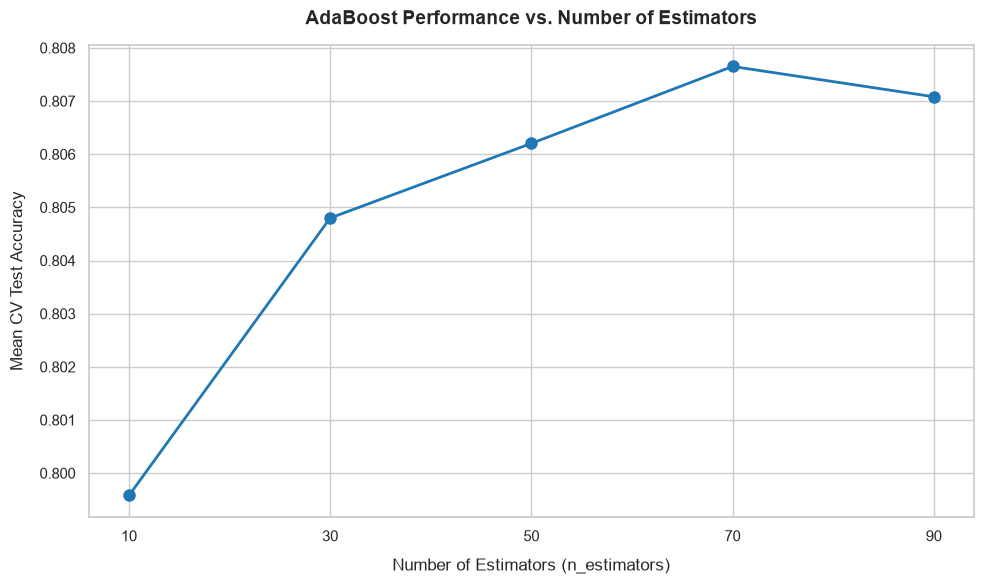

In [14]:
##10. Plot mean test scores
ada_scores_list = list(gs.cv_results_['mean_test_score'])

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
plt.plot(
    n_estimators_list,
    ada_scores_list,
    marker='o',
    linewidth=2,
    color='#1f77b4',
    markersize=8,
    label='AdaBoost Mean CV Score'
)
plt.title('AdaBoost Performance vs. Number of Estimators', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Number of Estimators (n_estimators)', fontsize=12, labelpad=10)
plt.ylabel('Mean CV Test Accuracy', fontsize=12, labelpad=10)
plt.xticks(n_estimators_list)
plt.tight_layout()
plt.show()

The most accurate AdaBoost classifier used 70 decision tree stumps. However, even at 70 stumps the model hardly did any better than with 10, only gaining about 0.8% accuracy.